In [21]:
from multi_func import *
import torch
from torch import nn, optim
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
import os

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

In [ ]:
bs = 32
LR = 1e-3
epoch = 30
cri = nn.CrossEntropyLoss()
nmt = True
mty = "MLP"
dataset = "CIFAR10"
os.makedirs("result", exist_ok=True)
smp = f"result/{mty}_{dataset}.pt"

In [23]:
trans = transforms.ToTensor()
trds = datasets.CIFAR10(root="data", train=True, download=False, transform=trans)
teds = datasets.CIFAR10(root="data", train=False, download=False, transform=trans)
trdl = DataLoader(trds, batch_size=bs, shuffle=True)
tedl = DataLoader(teds, batch_size=bs, shuffle=False)

automobile


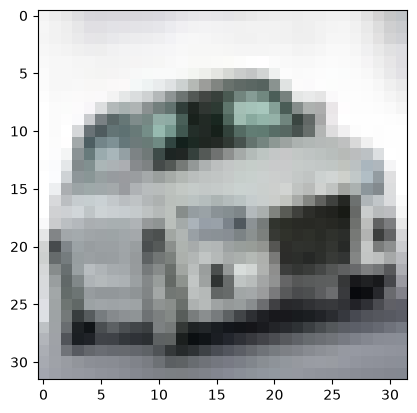

In [24]:
xb, yb = next(iter(trdl))
plt.imshow(xb[0].permute(1, 2, 0))
print(teds.classes[yb[0]])

In [25]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Sequential(
            nn.Linear(3 * 32 * 32, 30), nn.BatchNorm1d(30), nn.ReLU(), nn.Linear(30, 10)
        )

    def forward(self, x):
        x = torch.flatten(x, start_dim=1)
        x = self.linear(x)
        return x


class MLP_sh(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Sequential(
            nn.Linear(3 * 32 * 32, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Linear(256, 10),
        )

    def forward(self, x):
        x = torch.flatten(x, start_dim=1)
        x = self.linear(x)
        return x


class MLP_dr(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Sequential(
            nn.Linear(3 * 32 * 32, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            nn.Linear(256, 10),
        )

    def forward(self, x):
        x = torch.flatten(x, start_dim=1)
        x = self.linear(x)
        return x

In [26]:
model = globals()[mty]().to(DEVICE)
xb, _ = next(iter(trdl))

In [ ]:
if nmt:
    op = optim.Adam(model.parameters(), lr=LR)
    lh = Train(model, trdl, cri, op, epoch)
    torch.save(model, smp)
    plt.figure()
    plt.plot(range(1, epoch + 1), lh)
    plt.xlabel("epoch")
    plt.ylabel("loss")
    plt.title("train loss")
    plt.grid()

In [ ]:
lm = torch.load(smp, map_location=DEVICE, weights_only=False)

In [ ]:
Test(lm, tedl)
print(count_params(lm))

test accuracy: 4591/10000 0.5%
92560


In [ ]:
conf = get_conf(lm, tedl)
plot_conf_mat